# 11 — The decision system: the book a committee can choose, question, revise and evaluate

This notebook turns the corrected models into an evaluated decision process: the trade-off a committee chooses from, the questions it asks answered by the models, why each candidate is in or out, what waiting for information is worth, what revising the book two years in is worth, and which decision process does better on the same scenarios — with the AI advisor's contribution measured apart from the optimizer's. Everything here is a post-registration extension (decisions #88–#91); the registered record is in `results/registered_v7/`.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `results/candidate_npv.csv`, `results/scenario_settings.csv`, `data/interim/scenario_state.npz` | the forty candidates on 1 January 2025 (notebook 07) and every scenario draw (notebook 08) |
| in | `data/interim/trackA.parquet`, `data/interim/milestones.parquet` | the agreement signal's likelihoods from the queue history |
| in | `prompts/advisor_system.md`, `prompts/whatif_translate.md`, `prompts/whatif_explain.md`, `results/advisor_runs.jsonl` | the advisor with tools; every call recorded and replayable |
| out | `results/v8/base_books.csv`, `results/v8/frontier.csv`, `results/v8/policy_choice.csv` | the base books, the frontier over risk policies, which policy each committee would choose |
| out | `results/v8/whatifs.csv`, `results/v8/explanations.csv`, `results/v8/statuses.csv` | five committee questions; each candidate's opportunity cost; invest / stage / defer / monitor / reject |
| out | `results/v8/value_of_information.csv`, `results/v8/dynamic.csv`, `results/v8/process_comparison.csv`, `results/v8/value_added.csv` | information values; staged decisions; the decision processes compared |
| out | `results/v8/advisor_tools_eval.csv`, `results/v8/checks.csv` | the advisor with tools scored; checks |
| out | `figures/F38_frontier.*` … `figures/F44_advisor_tools.*` | report figures: frontier, reallocation, attractiveness, staged decisions, value added, the architecture, the advisor with tools |

*Execution order:* after notebooks 07–09. Paths are relative to the repository root.

## Setup

Two engines over the same forty candidates (`src/whatif.py`): one on the 2,000 primary scenarios, on which every book is chosen, and one on the 2,000 held-out scenarios, on which every book is scored. The held-out set redraws prices, output, costs and timing with its own seeds (audit A7). The main case is the committee grid and the contracted revenue case; the registered grid is reported beside it.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import advisor as adv, advisor_tools as at, config, decision_date, dynamic as dy, economics as ec, optimizer as opt, paths, plots, portfolio, voi, whatif as wi

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "11_decision_system"
START = time.time()
R = paths.RESULTS
V8 = R / "v8"
V8.mkdir(exist_ok=True)
registered = json.loads((R / "success_criteria_v7_registered.json").read_text(encoding="utf-8"))
LAM, LEVEL, CAP, SEED, N_BOOT = registered["lam"], registered["level"], 0.40, 2020, 2000
GRID = "committee"  # the main case; the registered grid is reported beside it
TECH_COLOR = {"Lease redevelopment": "#D55E00", "Gas CC": config.TECH_COLORS["Gas"], "Solar": config.TECH_COLORS["Solar"], "Wind": config.TECH_COLORS["Wind"], "Storage": config.TECH_COLORS["Battery"]}

sel = wi.Engine(2000, "primary")
held = wi.Engine(2000, "held-out")
ids = sel.ids
tech = sel.candidates["technology"].to_numpy()
sector = sel.candidates["sector"].to_numpy()
lease_mask = sector != "ERCOT power"
TECHS = list(TECH_COLOR)


def describe(x, A_h, charge, budget):
    """A book scored on the held-out scenarios: size, charge, mean, median, P(loss), CVaR, utilization, capital by technology."""
    x = np.asarray(x, int)
    total = A_h @ x
    return {"n": int(x.sum()), "leases": int(x[lease_mask].sum()), "requests": int(x[~lease_mask].sum()), "charge": float(charge @ x),
            "utilization": float(charge @ x / budget), **dy.summarize(total, LEVEL), "violations": len(opt.violations(x, charge, budget, tech, CAP)),
            **{f"charge_{t}": float(charge[tech == t] @ x[tech == t]) for t in TECHS}, "members": ";".join(np.array(ids)[x == 1])}


print(f"engines loaded: {len(ids)} candidates, {sel.prices.shape[0]:,} primary and {held.prices.shape[0]:,} held-out scenarios; {time.time() - START:.0f} s")

engines loaded: 40 candidates, 2,000 primary and 2,000 held-out scenarios; 2 s


## 0. The system in one picture

Six layers, each a module with tests; the language model sits in one of them and never produces a number the decision uses. The second diagram is the path a committee question takes.

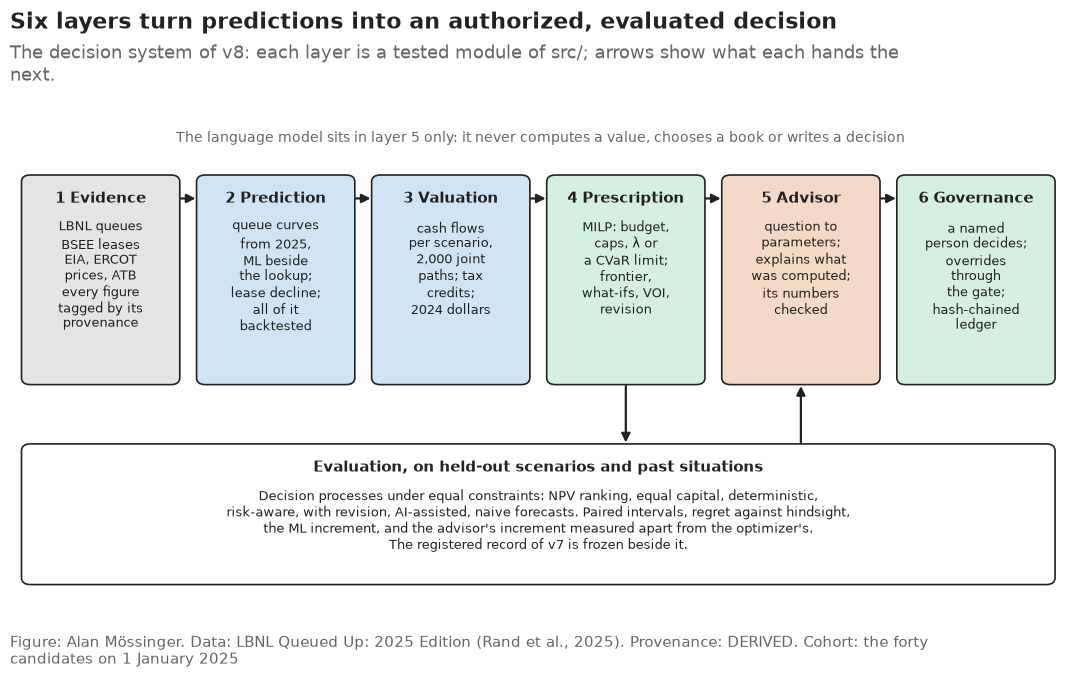

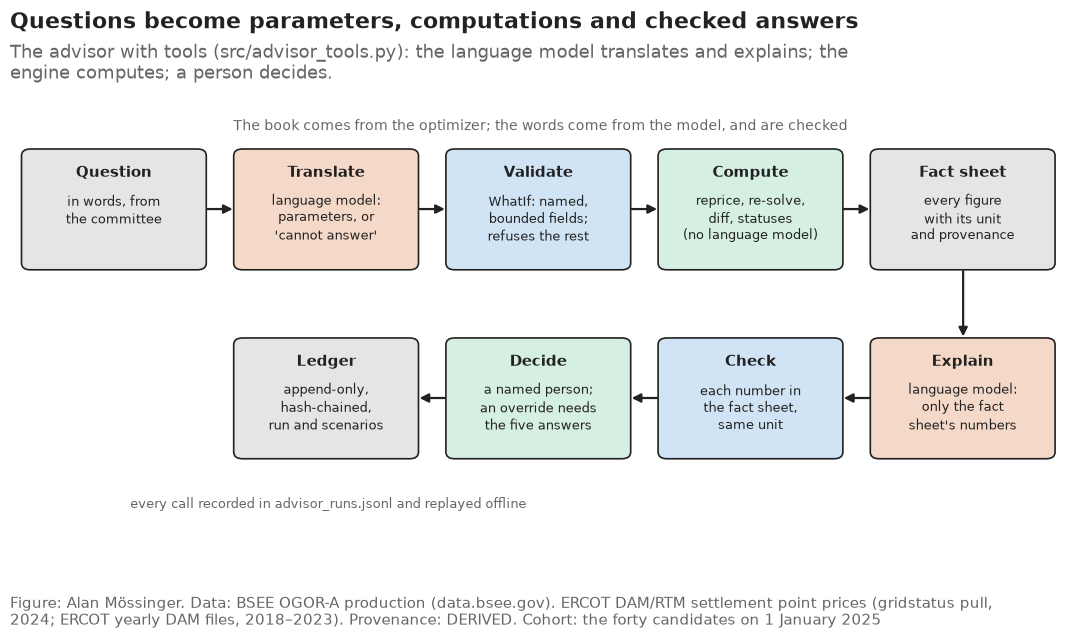

In [2]:
from matplotlib.patches import FancyBboxPatch

NL = chr(10)


def panel(ax, x, y, w, h, color, head, body, fs=10.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.1", facecolor=color, edgecolor=plots.INK, lw=1.2))
    ax.text(x + w / 2, y + h - 0.22, head, ha="center", va="top", fontsize=fs + 1.5, fontweight="bold", color=plots.INK)
    ax.text(x + w / 2, y + h - 0.62, body, ha="center", va="top", fontsize=fs, color=plots.INK, linespacing=1.3)


def arrow(ax, a, b, rad=0.0, text=None, tx=None, ty=None):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", lw=1.6, color=plots.INK, connectionstyle=f"arc3,rad={rad}"))
    if text:
        ax.text(tx, ty, text, ha="center", va="center", fontsize=9, color=plots.MUTED)


fig, ax = plt.subplots(figsize=(11, 6.8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 7)
ax.axis("off")
layers = [
    ("1 Evidence", ["LBNL queues", "BSEE leases", "EIA, ERCOT", "prices, ATB", "every figure", "tagged by its", "provenance"], "#E5E5E5"),
    ("2 Prediction", ["queue curves", "from 2025,", "ML beside", "the lookup;", "lease decline;", "all of it", "backtested"], "#D0E4F5"),
    ("3 Valuation", ["cash flows", "per scenario,", "2,000 joint", "paths; tax", "credits;", "2024 dollars"], "#D0E4F5"),
    ("4 Prescription", ["MILP: budget,", "caps, λ or", "a CVaR limit;", "frontier,", "what-ifs, VOI,", "revision"], "#D5F0E3"),
    ("5 Advisor", ["question to", "parameters;", "explains what", "was computed;", "its numbers", "checked"], "#F5D9C8"),
    ("6 Governance", ["a named", "person decides;", "overrides", "through", "the gate;", "hash-chained", "ledger"], "#D5F0E3"),
]
W, H, Y = 1.75, 3.0, 3.2
xs = [0.15 + i * 1.98 for i in range(6)]
for (head, body, color), x in zip(layers, xs):
    panel(ax, x, Y, W, H, color, head, NL.join(body), fs=9)
for i in range(5):
    arrow(ax, (xs[i] + W, Y + H - 0.32), (xs[i + 1], Y + H - 0.32))  # level with the headings, clear of the text
panel(ax, 0.15, 0.3, 11.65, 2.0, "#FFFFFF", "Evaluation, on held-out scenarios and past situations",
      NL.join(["Decision processes under equal constraints: NPV ranking, equal capital, deterministic,",
               "risk-aware, with revision, AI-assisted, naive forecasts. Paired intervals, regret against hindsight,",
               "the ML increment, and the advisor's increment measured apart from the optimizer's.",
               "The registered record of v7 is frozen beside it."]), fs=9)
arrow(ax, (xs[3] + W / 2, Y), (xs[3] + W / 2, 2.3))
arrow(ax, (xs[4] + W / 2, 2.3), (xs[4] + W / 2, Y))
ax.text(6.0, 6.7, "The language model sits in layer 5 only: it never computes a value, chooses a book or writes a decision", ha="center", fontsize=10, color=plots.MUTED)
plots.finish(fig, "Six layers turn predictions into an authorized, evaluated decision",
             "The decision system of v8: each layer is a tested module of src/; arrows show what each hands the next.",
             "the forty candidates on 1 January 2025", lbnl=True, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="DERIVED")
plots.save_fig(fig, "F43_architecture", "The decision system in six layers, and the evaluation that scores it.", NOTEBOOK)
plt.show()

fig, ax = plt.subplots(figsize=(11, 6.4))
ax.set_xlim(0, 12)
ax.set_ylim(0, 6.6)
ax.axis("off")
steps = [
    (0.15, 4.4, "Question", "in words, from" + NL + "the committee", "#E5E5E5"),
    (2.55, 4.4, "Translate", "language model:" + NL + "parameters, or" + NL + "'cannot answer'", "#F5D9C8"),
    (4.95, 4.4, "Validate", "WhatIf: named," + NL + "bounded fields;" + NL + "refuses the rest", "#D0E4F5"),
    (7.35, 4.4, "Compute", "reprice, re-solve," + NL + "diff, statuses" + NL + "(no language model)", "#D5F0E3"),
    (9.75, 4.4, "Fact sheet", "every figure" + NL + "with its unit" + NL + "and provenance", "#E5E5E5"),
    (9.75, 1.6, "Explain", "language model:" + NL + "only the fact" + NL + "sheet's numbers", "#F5D9C8"),
    (7.35, 1.6, "Check", "each number in" + NL + "the fact sheet," + NL + "same unit", "#D0E4F5"),
    (4.95, 1.6, "Decide", "a named person;" + NL + "an override needs" + NL + "the five answers", "#D5F0E3"),
    (2.55, 1.6, "Ledger", "append-only," + NL + "hash-chained," + NL + "run and scenarios", "#E5E5E5"),
]
for x, y, head, body, color in steps:
    panel(ax, x, y, 2.05, 1.75, color, head, body, fs=9.5)
for (x0, y0, *_), (x1, y1, *_) in zip(steps[:4], steps[1:5]):
    arrow(ax, (x0 + 2.05, y0 + 0.88), (x1, y1 + 0.88))
arrow(ax, (10.78, 4.4), (10.78, 3.35))
for (x0, y0, *_), (x1, y1, *_) in zip(steps[5:8], steps[6:9]):
    arrow(ax, (x0, y0 + 0.88), (x1 + 2.05, y1 + 0.88))
ax.text(3.6, 0.85, "every call recorded in advisor_runs.jsonl and replayed offline", ha="center", fontsize=9, color=plots.MUTED)
ax.text(6.0, 6.45, "The book comes from the optimizer; the words come from the model, and are checked", ha="center", fontsize=10, color=plots.MUTED)
plots.finish(fig, "Questions become parameters, computations and checked answers",
             "The advisor with tools (src/advisor_tools.py): the language model translates and explains; the engine computes; a person decides.",
             "the forty candidates on 1 January 2025", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="DERIVED")
plots.save_fig(fig, "F44_advisor_tools", "The path of a committee question through the advisor with tools, the engine, the check, the decision and the ledger.", NOTEBOOK)
plt.show()

**Reading this.** The architecture separates the three kinds of performance the evaluation measures: forecasting (layer 2, scored by backtests and against the lookup), optimization (layer 4, scored on held-out scenarios against the conventional books) and decision support (layers 5–6, scored on translation, grounding and refusals, with the book left to the optimizer and the decision to a person). The second picture is the only route by which a language model touches the numbers, and it never writes one: it chooses parameters a validator accepts or rejects, and it explains a fact sheet that a checker holds it to.

## 1. The base books

For each grid, the risk-aware MILP (λ = 1, the registered setting) under the two-stage budget: each candidate costs the budget its stage-one charge — a lease's capital, a request's deposits plus its construction reserve (decision #90) — and the budget is the registered rule in those units, 40% of the forty charges (decision #92); no technology above 40% of the budget. Chosen on the primary scenarios, scored on the held-out ones.

In [3]:
base = {}
rows = []
for grid in ("committee", "registered"):
    b = sel.base_case(grid, "contracted")
    A_h, _ = held.matrix(wi.WhatIf(grid=grid))
    base[grid] = {**b, "A_h": A_h}
    rows.append({"grid": grid, "budget": b["budget"], **describe(b["x"], A_h, b["charge"], b["budget"])})
base_books = pd.DataFrame(rows)
base_books.to_csv(V8 / "base_books.csv", index=False)
b = base[GRID]
A, A_h, charge, budget, x_D = b["A"], b["A_h"], b["charge"], b["budget"], b["x"]
print(f"{time.time() - START:.0f} s")
base_books.drop(columns="members").assign(**{c: base_books[c] / 1e9 for c in ("budget", "charge", "mean", "median", "cvar_loss") + tuple(f"charge_{t}" for t in TECHS)}).round(3)

68 s


,grid,budget,n,leases,requests,charge,utilization,mean,median,p_loss,cvar_loss,violations,charge_Lease redevelopment,charge_Gas CC,charge_Solar,charge_Wind,charge_Storage
0,committee,3.307,14,6,8,3.299,0.998,1.916,1.340,0.13,1.334,0,1.295,0.857,0.484,0.662,0.000
1,registered,1.793,21,13,8,1.668,0.931,7.594,7.079,0.00,-2.216,0,0.688,0.292,0.000,0.662,0.026


**Reading this.** Under the committee grid the risk-aware book spends almost the whole $3.31B budget on six leases and eight requests, expects $1.92B (median $1.34B) and loses money in 13% of held-out scenarios, with a worst-5% average loss of $1.33B. Under the registered grid, where a lease is cheap against the barrels it buys, the same rule holds thirteen leases and eight requests, expects $7.59B and almost never loses money. The two grids give different books, which is why both are shown: the committee grid is the one an investment committee would use, the registered grid the one fixed before any result. For a lender, the committee-grid book is a portfolio with a one-in-eight chance of losing money, not a safe one.

## 2. The trade-off a committee chooses from

The four books of the registration — **A** NPV ranking, **B** equal capital by sector, **C** the deterministic MILP, **D** the risk-aware MILP — are now held to the same budget and cap (audit A1). Beside them, the frontier: the MILP at nine values of λ and at hard limits on the worst-5% loss. Each committee weighs expected NPV against the tail differently; for a committee that maximizes E[NPV] − w × CVaR95, the last table says which policy it picks for each weight w. The framework does not choose w; it shows what each w buys. As a sensitivity, the four books are also solved at a budget of 40% of the candidates' full capital (decision #92), where nothing binds.

In [4]:
mu = A.mean(axis=0)
books = {"A NPV ranking": opt.top_n_by_npv(mu, charge, budget, groups=tech, group_cap=CAP),
         "B equal capital by sector": opt.equal_capital_by_sector(mu, charge, sector, budget, groups=tech, group_cap=CAP),
         "C deterministic MILP": opt.solve_milp(A, charge, budget, lam=0.0, level=LEVEL, groups=tech, group_cap=CAP)["x"],
         "D risk-aware MILP": x_D}
front = []
for lam in (0, 0.25, 0.5, 1, 2, 4, 8, 16, 32):
    x = opt.solve_milp(A, charge, budget, lam=lam, level=LEVEL, groups=tech, group_cap=CAP)["x"]
    front.append({"policy": f"lambda {lam:g}", "kind": "penalty", "setting": lam, **describe(x, A_h, charge, budget)})
cvar_D = opt.cvar(-(A @ x_D), LEVEL)
for share in (0.75, 0.5, 0.25, 0.1):
    limit = cvar_D * share if cvar_D > 0 else cvar_D - abs(cvar_D) * (1 - share)
    try:
        x = opt.solve_milp(A, charge, budget, lam=0.0, level=LEVEL, groups=tech, group_cap=CAP, cvar_cap=limit)["x"]
        front.append({"policy": f"CVaR limit {share:.0%} of D", "kind": "limit", "setting": limit, **describe(x, A_h, charge, budget)})
    except opt.InfeasibleBook:
        front.append({"policy": f"CVaR limit {share:.0%} of D", "kind": "limit", "setting": limit, "n": 0, "members": "no feasible book"})
for name, x in books.items():
    front.append({"policy": name, "kind": "comparator", "setting": np.nan, **describe(x, A_h, charge, budget)})
# sensitivity (decision #92): the budget at 40% of full capital instead of 40% of stage-one charges
budget_capital = 0.40 * sel.capital(wi.WhatIf(grid=GRID)).sum()
for name, x in {"A NPV ranking": opt.top_n_by_npv(mu, charge, budget_capital, groups=tech, group_cap=CAP),
                "B equal capital by sector": opt.equal_capital_by_sector(mu, charge, sector, budget_capital, groups=tech, group_cap=CAP),
                "C deterministic MILP": opt.solve_milp(A, charge, budget_capital, lam=0.0, level=LEVEL, groups=tech, group_cap=CAP)["x"],
                "D risk-aware MILP": opt.solve_milp(A, charge, budget_capital, lam=LAM, level=LEVEL, groups=tech, group_cap=CAP)["x"]}.items():
    front.append({"policy": f"{name}, budget 40% of capital", "kind": "sensitivity", "setting": budget_capital, **describe(x, A_h, charge, budget_capital)})
frontier = pd.DataFrame(front)
frontier.to_csv(V8 / "frontier.csv", index=False)
feasible = frontier[frontier["kind"].isin(["penalty", "limit"])].dropna(subset=["mean"]).drop_duplicates(subset=["members"])
choice = []
for w in np.round(np.arange(0, 10.01, 0.25), 2):
    utility = feasible["mean"] - w * feasible["cvar_loss"]
    best = feasible.loc[utility.idxmax()]
    choice.append({"tail_weight_w": w, "policy": best["policy"], "mean": best["mean"], "cvar_loss": best["cvar_loss"], "members": best["members"]})
policy_choice = pd.DataFrame(choice)
policy_choice.to_csv(V8 / "policy_choice.csv", index=False)
switches = policy_choice[policy_choice["policy"] != policy_choice["policy"].shift()]
print(f"{len(feasible)} distinct frontier books; the choice changes at w = {switches['tail_weight_w'].tolist()}; {time.time() - START:.0f} s")
frontier.drop(columns="members").assign(**{c: frontier[c] / 1e9 for c in ("charge", "mean", "median", "cvar_loss")}).round(3)

12 distinct frontier books; the choice changes at w = [0.0, 0.25, 0.75, 1.0, 1.5, 2.5, 2.75, 4.25, 5.0]; 128 s


,policy,kind,setting,n,leases,requests,charge,utilization,mean,median,p_loss,cvar_loss,violations,charge_Lease redevelopment,charge_Gas CC,charge_Solar,charge_Wind,charge_Storage
0,lambda 0,penalty,0.000000e+00,18,5,13,3.229,0.976,2.121,1.413,0.142,1.690,0,1.314855e+09,1.159141e+09,0.000000e+00,6.624300e+08,9.271683e+07
1,lambda 0.25,penalty,2.500000e-01,16,5,11,3.163,0.956,2.118,1.413,0.140,1.650,0,1.314855e+09,1.159141e+09,0.000000e+00,6.624300e+08,2.653476e+07
2,lambda 0.5,penalty,5.000000e-01,14,5,9,2.981,0.901,1.977,1.365,0.138,1.470,0,1.314855e+09,9.768361e+08,0.000000e+00,6.624300e+08,2.653476e+07
3,lambda 1,penalty,1.000000e+00,14,6,8,3.299,0.998,1.916,1.340,0.130,1.334,0,1.295257e+09,8.568725e+08,4.841149e+08,6.624300e+08,0.000000e+00
4,lambda 2,penalty,2.000000e+00,8,3,5,1.238,0.374,0.839,0.590,0.092,0.259,0,5.750960e+08,0.000000e+00,0.000000e+00,6.624300e+08,0.000000e+00
5,lambda 4,penalty,4.000000e+00,5,0,5,0.662,0.200,0.387,-0.005,0.679,0.077,0,0.000000e+00,0.000000e+00,0.000000e+00,6.624300e+08,0.000000e+00
6,lambda 8,penalty,8.000000e+00,4,0,4,0.577,0.175,0.344,-0.003,0.706,0.066,0,0.000000e+00,0.000000e+00,0.000000e+00,5.773659e+08,0.000000e+00
7,lambda 16,penalty,1.600000e+01,1,0,1,0.042,0.013,0.020,-0.001,0.973,0.001,0,0.000000e+00,0.000000e+00,0.000000e+00,4.168718e+07,0.000000e+00
8,lambda 32,penalty,3.200000e+01,1,0,1,0.042,0.013,0.020,-0.001,0.973,0.001,0,0.000000e+00,0.000000e+00,0.000000e+00,4.168718e+07,0.000000e+00
9,CVaR limit 75% of D,limit,8.844766e+08,15,5,10,2.878,0.870,1.655,1.280,0.116,0.983,0,1.314855e+09,3.895983e+08,4.841149e+08,6.624300e+08,2.653476e+07


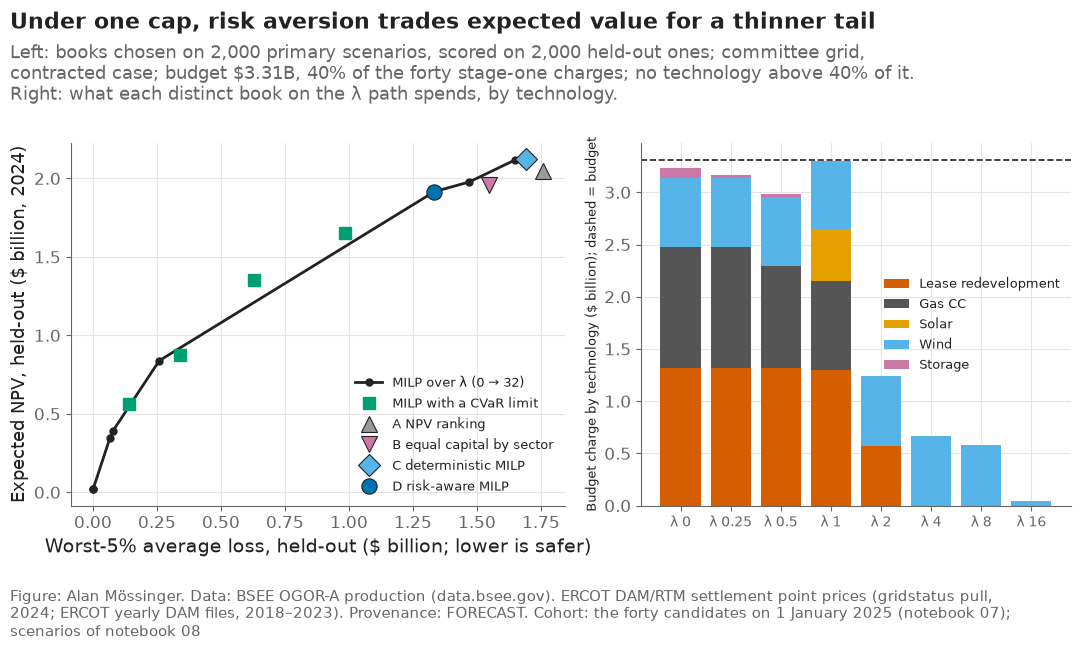

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})
f = frontier[frontier["kind"] == "penalty"].sort_values("setting")
axes[0].plot(f["cvar_loss"] / 1e9, f["mean"] / 1e9, "-o", color=plots.INK, lw=2, ms=5, label="MILP over λ (0 → 32)")
lim = frontier[(frontier["kind"] == "limit") & frontier["mean"].notna()]
axes[0].plot(lim["cvar_loss"] / 1e9, lim["mean"] / 1e9, "s", color="#009E73", ms=8, label="MILP with a CVaR limit")
marks = {"A NPV ranking": ("#999999", "^"), "B equal capital by sector": ("#CC79A7", "v"), "C deterministic MILP": ("#56B4E9", "D"), "D risk-aware MILP": ("#0072B2", "o")}
for name, (col, m) in marks.items():
    r = frontier[(frontier["policy"] == name)].iloc[0]
    axes[0].plot(r["cvar_loss"] / 1e9, r["mean"] / 1e9, m, color=col, ms=11, mec=plots.INK, mew=0.8, label=name, zorder=3)
axes[0].set_xlabel("Worst-5% average loss, held-out ($ billion; lower is safer)")
axes[0].set_ylabel("Expected NPV, held-out ($ billion, 2024)")
axes[0].legend(loc="lower right", fontsize=9.5)
show = f.drop_duplicates(subset=["members"])
bottom = np.zeros(len(show))
for t in TECHS:
    vals = show[f"charge_{t}"].to_numpy() / 1e9
    axes[1].bar(np.arange(len(show)), vals, bottom=bottom, color=TECH_COLOR[t], label=t)
    bottom += vals
axes[1].set_xticks(np.arange(len(show)), [p.replace("lambda ", "λ ") for p in show["policy"]], fontsize=10)
axes[1].axhline(budget / 1e9, color=plots.INK, ls="--", lw=1.2)
axes[1].set_ylabel("Budget charge by technology ($ billion); dashed = budget")
axes[1].legend(loc="center right", fontsize=9)
plots.finish(fig, "Under one cap, risk aversion trades expected value for a thinner tail",
             f"Left: books chosen on 2,000 primary scenarios, scored on 2,000 held-out ones; committee grid, contracted case; budget ${budget / 1e9:.2f}B, 40% of the forty stage-one charges; no technology above 40% of it. "
             "Right: what each distinct book on the λ path spends, by technology.",
             "the forty candidates on 1 January 2025 (notebook 07); scenarios of notebook 08", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F38_frontier", "The efficient frontier over risk policies, the four registered books on it, and capital by technology along it.", NOTEBOOK)
plt.show()

**Reading this.** Along the λ path, expected value and tail fall together: $2.12B with a $1.69B worst-5% loss at λ = 0, $1.92B and $1.33B at λ = 1, $0.84B and $0.26B at λ = 2; beyond λ = 4 the book holds only wind and expects little. The CVaR-limit books sit above the λ path on the held-out scenarios: books chosen on one scenario set and scored on another need not trace one curve. Under equal constraints NPV ranking (A) and the deterministic book (C) sit at the high-return end, equal capital (B) and the risk-aware book (D) between. The policy-choice table shows which book each tail weight w picks — the framework does not choose w, the committee does. As a sensitivity, at a budget of 40% of full capital nothing binds and A, B and C fund the same 34 candidates, a comparison with nothing to compare (decision #92).

## 3. Five questions a committee asks, answered by the models

Each question is a `WhatIf` — validated parameters, not prose — and the engine reprices every candidate, re-solves the book on the primary scenarios and scores it on the held-out ones. The stricter downside limit is half the worst-5% loss of book D.

In [6]:
QUESTIONS = {
    "WTI at $45 a barrel for five years": wi.WhatIf(wti_level=45.0, wti_years=5),
    "ERCOT prices half as volatile": wi.WhatIf(ercot_volatility=0.5),
    "the budget cut by a fifth": wi.WhatIf(budget_multiplier=0.8),
    "offshore redevelopment capital up 30%": wi.WhatIf(lease_cost_multiplier=1.3),
    "worst-5% loss at most half of book D's": wi.WhatIf(cvar_limit_musd=0.5 * cvar_D / 1e6),
}
answers, w_rows = {}, []
for q, w in QUESTIONS.items():
    res = sel.run(w)
    A_hw, charge_w = held.matrix(w)
    row = {"question": q, "changes": json.dumps(w.changes()), "feasible": res["feasible"], "reason": res["reason"]}
    if res["feasible"]:
        x_w = res["candidates"]["in_book"].to_numpy(int)
        new = describe(x_w, A_hw, charge_w, res["budget"])
        old = describe(x_D, A_hw, charge_w, res["budget"])  # book D held under the new conditions, for comparison
        d = res["diff"]
        row.update({"entered": ";".join(d["entered"]), "left": ";".join(d["left"]), "n_entered": len(d["entered"]), "n_left": len(d["left"]),
                    "mean_new": new["mean"], "mean_book_D_held": old["mean"], "cvar_new": new["cvar_loss"], "cvar_book_D_held": old["cvar_loss"],
                    "p_loss_new": new["p_loss"], "hhi_change": d["change"]["hhi"], **{f"charge_{t}_new": new[f"charge_{t}"] for t in TECHS}})
        answers[q] = {"result": res, "x": x_w}
    w_rows.append(row)
whatifs = pd.DataFrame(w_rows)
whatifs.to_csv(V8 / "whatifs.csv", index=False)
print(f"{time.time() - START:.0f} s")
whatifs.drop(columns=["changes", "entered", "left"]).assign(**{c: whatifs[c] / 1e9 for c in whatifs.columns if c.startswith(("mean", "cvar", "charge"))}).round(3)

296 s


,question,feasible,reason,n_entered,n_left,mean_new,mean_book_D_held,cvar_new,cvar_book_D_held,p_loss_new,hhi_change,charge_Lease redevelopment_new,charge_Gas CC_new,charge_Solar_new,charge_Wind_new,charge_Storage_new
0,WTI at $45 a barrel for five years,True,None,0,9,0.387,1.268,0.077,1.720,0.679,0.716,0.000,0.0,0.000,0.662,0.000
1,ERCOT prices half as volatile,True,None,1,4,1.288,1.298,0.552,1.085,0.102,0.263,1.248,0.0,0.000,0.662,0.000
2,the budget cut by a fifth,True,None,1,5,1.127,1.916,0.424,1.334,0.095,0.216,0.944,0.0,0.000,0.662,0.027
3,offshore redevelopment capital up 30%,True,None,0,9,0.387,1.499,0.077,1.807,0.679,0.688,0.000,0.0,0.000,0.662,0.000
4,worst-5% loss at most half of book D's,True,None,2,3,1.355,1.916,0.624,1.334,0.102,0.097,1.248,0.0,0.484,0.662,0.027


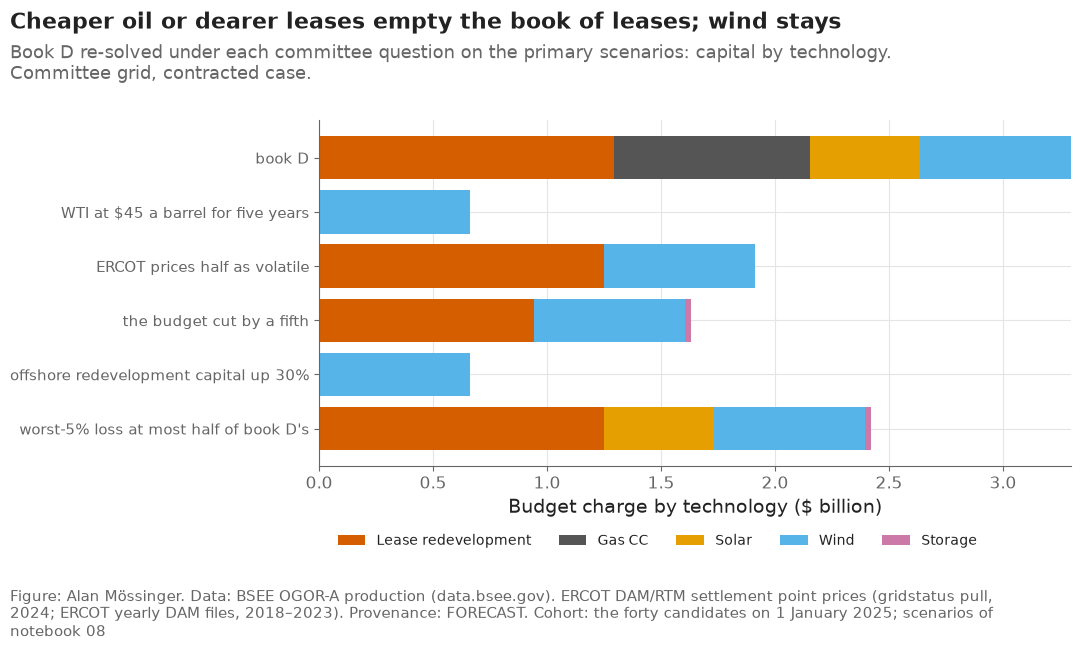

In [7]:
fig, ax = plt.subplots(figsize=(11, 6.5))
labels = ["book D"] + [q for q in QUESTIONS if q in answers]
stack = [describe(x_D, A_h, charge, budget)] + [whatifs.set_index("question").loc[q] for q in QUESTIONS if q in answers]
bottom = np.zeros(len(labels))
for t in TECHS:
    vals = np.array([s[f"charge_{t}"] if i == 0 else s[f"charge_{t}_new"] for i, s in enumerate(stack)]) / 1e9
    ax.barh(np.arange(len(labels)), vals, left=bottom, color=TECH_COLOR[t], label=t)
    bottom += vals
ax.set_yticks(np.arange(len(labels)), labels, fontsize=11)
ax.invert_yaxis()
ax.set_xlabel("Budget charge by technology ($ billion)")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.16), ncol=5, fontsize=10, frameon=False)  # below the axis, clear of every bar
plots.finish(fig, "Cheaper oil or dearer leases empty the book of leases; wind stays",
             "Book D re-solved under each committee question on the primary scenarios: capital by technology. Committee grid, contracted case.",
             "the forty candidates on 1 January 2025; scenarios of notebook 08", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F39_reallocation", "How the book's capital moves under five committee questions.", NOTEBOOK)
plt.show()

**Reading this.** The book is most sensitive to the lease economics: oil at $45 for five years or redevelopment capital 30% higher removes all six leases, both gas requests and the solar request, leaving the wind requests, a book that expects $0.39B and loses money in 68% of held-out scenarios but whose worst-5% loss is small, because it is small. Halving ERCOT's volatility drops the gas requests and the agreement-backed solar request, whose value rests on price spikes. A budget cut of a fifth drops two leases and three requests and adds a storage request. Capping the worst-5% loss at half of book D's swaps the gas requests and one lease for another lease and a storage request. For a committee the first two answers matter most: the leases are the book's value, and they rest on an assumed cost and a sustained oil price.

## 4. Why each candidate is in or out

For every candidate, the book is re-solved with it forced the other way; the drop in E[NPV] − λ·CVaR is its opportunity cost (`whatif.explain`). This is a model-supported explanation: it says what the optimizer gives up on these scenarios and costs, not why a project would succeed.

In [8]:
w0 = wi.WhatIf(grid=GRID)
explanations = wi.explain(sel, w0, x_D, A, charge, budget)
status = sel.status_table(A, charge, x_D)
explanations = explanations.merge(status[["project_id", "technology", "charge_$M", "expected_npv_$M", "median_npv_$M", "p_negative", "status"]], on="project_id")
explanations["held_q05_$M"] = np.quantile(A_h, 0.05, axis=0) / 1e6
explanations["held_q95_$M"] = np.quantile(A_h, 0.95, axis=0) / 1e6
explanations.to_csv(V8 / "explanations.csv", index=False)
print(f"{time.time() - START:.0f} s")
explanations.sort_values("objective_cost_$M", ascending=False).head(15).round(1)

454 s


,project_id,in_book,objective_cost_$M,expected_npv_change_$M,cvar_change_$M,note,technology,charge_$M,expected_npv_$M,median_npv_$M,p_negative,status,held_q05_$M,held_q95_$M
23,REQ|ERCOT|26INR0113,True,373.4,-780.6,-407.2,,Wind,396.9,262.6,-0.7,0.7,invest now,-0.7,1370.0
1,LEASE|G15607,False,339.2,-224.3,114.9,,Lease redevelopment,391.7,60.8,30.8,0.4,monitor,-257.7,470.8
2,LEASE|G20082,False,137.5,-88.1,49.3,,Lease redevelopment,460.5,221.6,174.3,0.3,monitor,-217.5,888.1
6,LEASE|G07957,False,90.4,-169.7,-79.3,,Lease redevelopment,239.9,67.6,47.4,0.3,monitor,-132.5,352.6
19,LEASE|G17001,False,80.9,-56.8,24.0,,Lease redevelopment,98.7,1.5,-2.8,0.5,monitor,-69.4,90.6
12,LEASE|G15610,False,80.3,-77.6,2.6,,Lease redevelopment,148.2,37.6,25.9,0.4,monitor,-86.3,202.1
5,LEASE|G21245,False,71.2,-76.0,-4.8,,Lease redevelopment,274.3,127.9,100.5,0.2,monitor,-123.3,481.5
13,LEASE|G07962,False,69.8,-72.9,-3.1,,Lease redevelopment,130.0,42.3,31.0,0.3,monitor,-76.9,209.1
24,REQ|ERCOT|26INR0155,False,66.5,-151.5,-85.0,,Solar,211.2,-10.5,-0.9,0.9,reject,-48.8,102.1
22,REQ|ERCOT|26INR0046,False,66.5,-158.2,-91.7,,Solar,172.8,-17.2,-0.9,1.0,reject,-226.9,-0.9


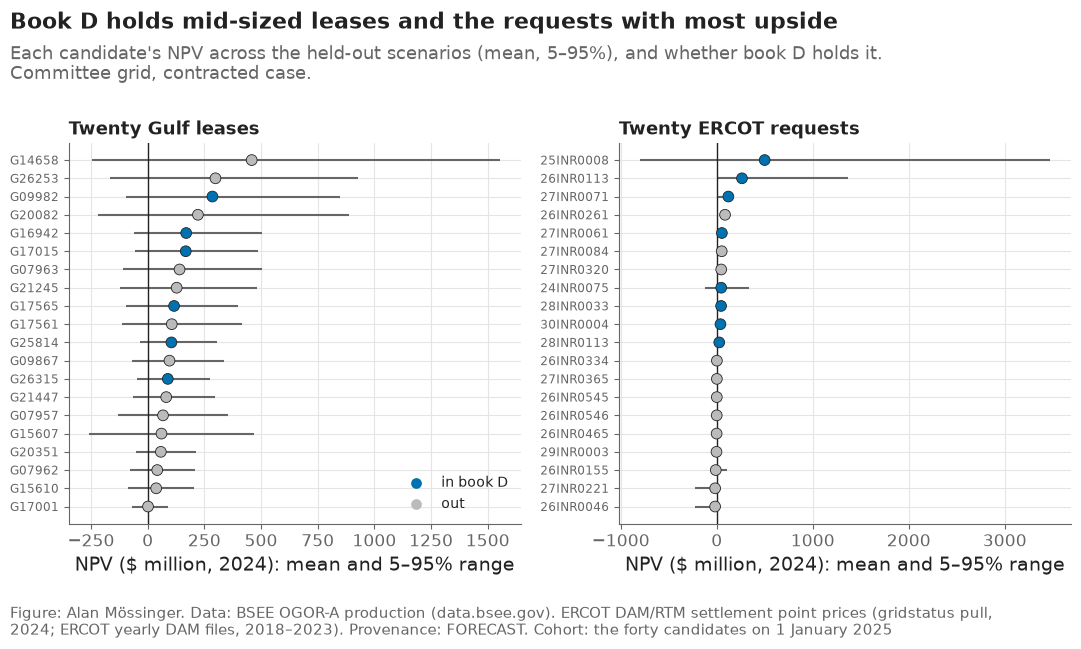

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
for ax, mask, title in ((axes[0], lease_mask, "Twenty Gulf leases"), (axes[1], ~lease_mask, "Twenty ERCOT requests")):
    e = explanations[mask].sort_values("expected_npv_$M")
    y = np.arange(len(e))
    colors = np.where(e["in_book"], "#0072B2", "#BBBBBB")
    ax.hlines(y, e["held_q05_$M"], e["held_q95_$M"], color=plots.MUTED, lw=1.5)
    ax.scatter(e["expected_npv_$M"], y, c=colors, s=60, zorder=3, edgecolor=plots.INK, linewidth=0.6)
    ax.set_yticks(y, [p.split("|")[-1] for p in e["project_id"]], fontsize=8.5)
    ax.axvline(0, color=plots.INK, lw=1)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("NPV ($ million, 2024): mean and 5–95% range")
axes[0].scatter([], [], c="#0072B2", s=60, edgecolor=plots.INK, label="in book D")
axes[0].scatter([], [], c="#BBBBBB", s=60, edgecolor=plots.INK, label="out")
axes[0].legend(loc="lower right", fontsize=10)
plots.finish(fig, "Book D holds mid-sized leases and the requests with most upside",
             "Each candidate's NPV across the held-out scenarios (mean, 5–95%), and whether book D holds it. Committee grid, contracted case.",
             "the forty candidates on 1 January 2025", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F40_attractiveness", "Project-level value and uncertainty, and membership of book D.", NOTEBOOK)
plt.show()

**Reading this.** The largest opportunity cost belongs to an agreement-backed wind request: forcing it out lowers the objective by $373M. The largest gas request (1,350 MW, four years in the queue) expects $499M on the primary scenarios yet loses money in 78% of them; it earns its place through rare large outcomes, so its value rests on ERCOT's price spikes recurring. Several leases out of the book carry positive expected value — the cap and the tail kept them out — and are marked monitor. The explanations say what the optimizer gives up on these scenarios and costs; they do not say why a project would succeed.

## 5. What information is worth

The gain in the best book's expected NPV from deciding after the information rather than before (`src/voi.py`), risk-neutral (λ = 0), under the same budget and caps, on the primary scenarios. Perfect information about everything (EVPI) is the ceiling; partial EVPIs value learning one block — the 2025–2029 oil, gas or power price level, the lease cost draw, a request's completion. One signal can actually be waited for: whether a request signs its agreement within two years. Its likelihoods come from ERCOT's history — requests of 20 MW and more waiting without an agreement on 1 January 2018, by whether they operated by the end of 2024 — and its EVSI is computed by preposterior reweighting. No public file prices the information, so each value is the most a committee should pay for it. A request out of the book whose signal is worth more than its deposit is marked *defer pending information*.

In [10]:
track = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
ms = pd.read_parquet(paths.DATA_INTERIM / "milestones.parquet").set_index("project_key")
ia = pd.Series(track["project_key"].astype(str).map(ms["ia_date_best"].where(ms["ia_inside_queue"])).to_numpy(), index=track.index)
hist_date = pd.Timestamp("2018-01-01")
pool = decision_date.live_on(track, hist_date)
pool = pool[(pool["region"] == "ERCOT") & (pool["mw"] >= config.FERC_SIZE_STEP_MW)]
no_ia = ~(ia.reindex(pool.index).notna() & (ia.reindex(pool.index) < hist_date))
pool = pool[no_ia.to_numpy()]
signed2 = (ia.reindex(pool.index) < hist_date + pd.DateOffset(years=2)).fillna(False).to_numpy()
operated = decision_date.observed_within(track.loc[pool.index], hist_date, 7).to_numpy().astype(bool)
Q_BUILT, Q_NOT = float(signed2[operated].mean()), float(signed2[~operated].mean())
print(f"ERCOT history, {len(pool):,} requests waiting without an agreement on {hist_date:%Y-%m-%d}: P(agreement within 2 y | operated) = {Q_BUILT:.2f} "
      f"(n {int(operated.sum())}), P(… | not operated) = {Q_NOT:.2f} (n {int((~operated).sum())})")

rows = []
total = voi.evpi_total(A, charge, budget, tech, CAP)
rows.append({"information": "everything (perfect information)", "kind": "EVPI", "value": total["evpi"], "prior_value": total["prior_value"]})
blocks = {"oil price level 2025–2029": sel.prices[:, :60, 0].mean(axis=1), "gas price level 2025–2029": sel.prices[:, :60, 1].mean(axis=1),
          "ERCOT price level 2025–2029": sel.prices[:, :60, 2].mean(axis=1), "lease cost draw": sel.cost_mult}
for name, values in blocks.items():
    r = voi.evpi_partition(A, charge, budget, voi.deciles(values), tech, CAP)
    rows.append({"information": name, "kind": "partial EVPI (deciles)", "value": r["evpi"], "prior_value": r["prior_value"]})
power_ids = list(sel.power["project_id"])
for k, pid in enumerate(power_ids):
    state = sel.op_year[:, k] > 0
    perfect = voi.evpi_partition(A, charge, budget, state, tech, CAP)
    sample = voi.evsi_signal(A, charge, budget, state, {True: Q_BUILT, False: Q_NOT}, tech, CAP)
    carry = float(sel.power.loc[k, "carry_cost"])
    rows.append({"information": f"{pid}: completion", "kind": "partial EVPI", "value": perfect["evpi"], "prior_value": perfect["prior_value"], "project_id": pid})
    rows.append({"information": f"{pid}: agreement within two years", "kind": "EVSI", "value": sample["evsi"], "prior_value": sample["prior_value"], "project_id": pid,
                 "p_signal": sample["p_signal"], "carry": carry})
value_of_information = pd.DataFrame(rows)
value_of_information.to_csv(V8 / "value_of_information.csv", index=False)
statuses = status.copy()
evsi = value_of_information[value_of_information["kind"] == "EVSI"].set_index("project_id")
wait = statuses["project_id"].isin(evsi.index[evsi["value"] > evsi["carry"]]) & ~statuses["in_book"]
statuses.loc[wait, "status"] = "defer pending information"
statuses.to_csv(V8 / "statuses.csv", index=False)
print(f"{time.time() - START:.0f} s; statuses: {statuses['status'].value_counts().to_dict()}")
(value_of_information.groupby("kind")["value"].agg(["count", "mean", "max"]) / [1, 1e6, 1e6]).round(1)

ERCOT history, 566 requests waiting without an agreement on 2018-01-01: P(agreement within 2 y | operated) = 0.89 (n 57), P(… | not operated) = 0.05 (n 509)


482 s; statuses: {'monitor': 17, 'invest now': 8, 'invest in stages': 6, 'defer pending information': 6, 'reject': 3}


,count,mean,max
kind,,,
EVPI,1.0,481.5,481.5
EVSI,20.0,1.0,4.8
partial EVPI,20.0,5.5,32.9
partial EVPI (deciles),4.0,23.8,40.0


**Reading this.** Perfect information about everything would raise the best book's expected value by at most $482M; that is the ceiling on what any study, survey or delay could be worth. Of the blocks, the 2025–2029 ERCOT price level is worth most ($40M), then oil ($22M), the lease cost draw ($18M) and gas ($15M). Learning within two years whether a request signs its agreement is worth $0.07M to $4.8M depending on the request; for six requests outside the book that exceeds the deposit needed to keep them alive, so their status is defer pending information. No public file prices any of this information, so each figure is the most a committee should pay, not a return.

## 6. Staged decisions: commit, learn, revise (a scenario-based extension)

On 1 January 2025 the company funds book D's leases and pays its requests' deposits. On 1 January 2027 each scenario has revealed two years of prices and, for each request, whether it signed its agreement (drawn with the likelihoods of section 5). The company drops a request whose expected value given that information is below walking away plus what its released reserve could earn in a deferred lease, and starts deferred leases with the capital released (`src/dynamic.py`). The continuation values are least-squares regressions fitted on the primary scenarios; the policy is scored on the held-out scenarios. Switching costs other than the lost deposit are not modelled, and nothing here establishes real future costs or real-option values: it is what flexibility is worth inside the model.

In [11]:
g = sel.grid(w0)
A_def = dy.deferred_lease_matrix(sel.baselines, sel.wells, sel.prices, sel.out_lease, sel.cost_mult, ec.grid_case("base"), grid=g)
A_def_h = dy.deferred_lease_matrix(held.baselines, held.wells, held.prices, held.out_lease, held.cost_mult, ec.grid_case("base"), grid=g)
sig = dy.agreement_signal(sel.op_year, Q_BUILT, Q_NOT, seed=SEED)
sig_h = dy.agreement_signal(held.op_year, Q_BUILT, Q_NOT, seed=SEED + 1)
carry = sel.power["carry_cost"].to_numpy(float)
fit = dy.staged_policy(x_D, A, A_def, carry, charge, budget, lease_mask, sel.op_year, sig, sel.prices, fit=True, lease_cap=CAP)
staged = dy.staged_policy(x_D, A_h, A_def_h, carry, charge, budget, lease_mask, held.op_year, sig_h, held.prices, models=fit["models"], lease_cap=CAP)
static = A_h @ x_D
gain = staged["payoff"] - static
draws = np.random.default_rng(SEED).choice(gain, size=(N_BOOT, len(gain))).mean(axis=1)
power_idx = np.where(~lease_mask)[0]
built_h = held.op_year > 0
drawn = np.array([sum(sel.power.loc[k, "capex"] for k, j in enumerate(power_idx) if x_D[j] and built_h[s, k]) for s in range(len(static))])
reserve = sum(sel.power.loc[k, "capex"] * sel.power.loc[k, "p_operation_7y"] for k, j in enumerate(power_idx) if x_D[j])
dynamic = pd.DataFrame([
    {"policy": "static book D (commit in 2025, never revise)", **dy.summarize(static, LEVEL), "dropped": 0.0, "started": 0.0, "redeployed": 0.0},
    {"policy": "staged: book D, revised on 1 January 2027", **dy.summarize(staged["payoff"], LEVEL), "dropped": staged["dropped"].mean(), "started": staged["started"].mean(),
     "redeployed": staged["redeployed"].mean()},
])
dynamic["value_of_flexibility"] = [0.0, gain.mean()]
dynamic["flex_low"], dynamic["flex_high"] = [0.0, np.percentile(draws, 2.5)], [0.0, np.percentile(draws, 97.5)]
dynamic["share_scenarios_revised"] = [0.0, float(((staged["dropped"] + staged["started"]) > 0).mean())]
dynamic["construction_over_reserve_share"] = [float((drawn > reserve).mean()), np.nan]
dynamic.to_csv(V8 / "dynamic.csv", index=False)
print(f"value of flexibility ${gain.mean() / 1e6:,.0f}M [{np.percentile(draws, 2.5) / 1e6:,.0f}M, {np.percentile(draws, 97.5) / 1e6:,.0f}M]; "
      f"revised in {dynamic.loc[1, 'share_scenarios_revised']:.0%} of held-out scenarios; construction exceeds the reserve in {dynamic.loc[0, 'construction_over_reserve_share']:.0%}; {time.time() - START:.0f} s")
dynamic.assign(**{c: dynamic[c] / 1e9 for c in ("mean", "median", "cvar_loss", "redeployed", "value_of_flexibility", "flex_low", "flex_high")}).round(3)

value of flexibility $-13M [-24M, -4M]; revised in 78% of held-out scenarios; construction exceeds the reserve in 45%; 507 s


,policy,mean,median,p_loss,cvar_loss,dropped,started,redeployed,value_of_flexibility,flex_low,flex_high,share_scenarios_revised,construction_over_reserve_share
0,"static book D (commit in 2025, never revise)",1.916,1.340,0.13,1.334,0.000,0.0,0.0,0.000,0.000,0.000,0.000,0.454
1,"staged: book D, revised on 1 January 2027",1.903,1.343,0.13,1.332,1.412,0.0,0.0,-0.013,-0.024,-0.004,0.784,NaN


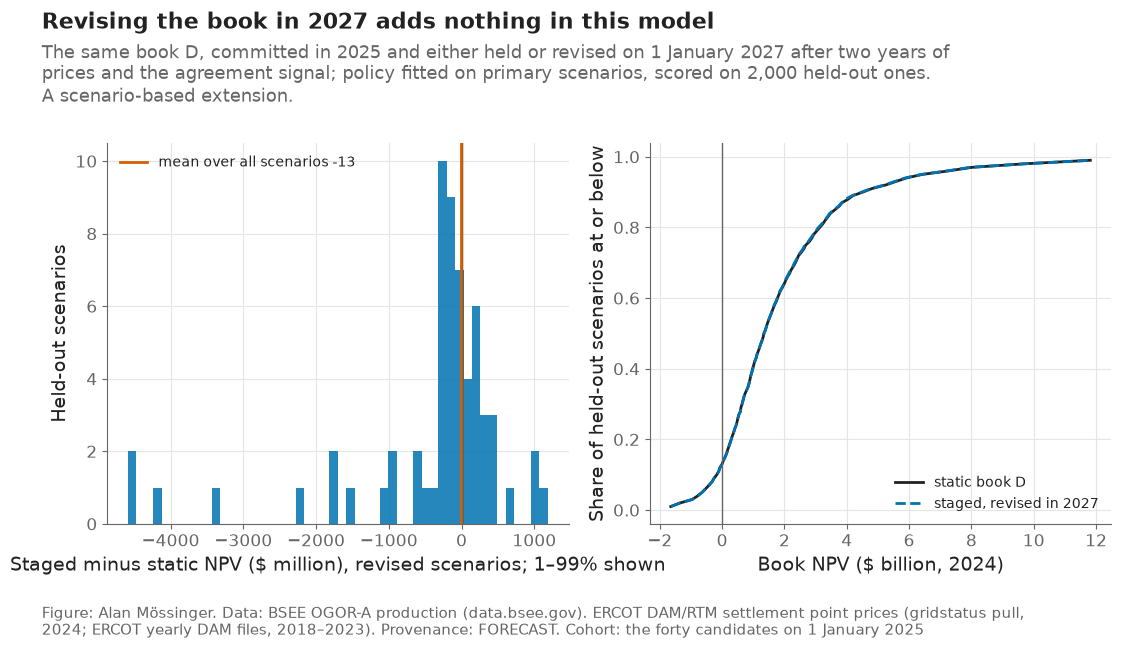

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
changed = gain[np.abs(gain) > 1.0]  # scenarios where the revision did something
lo, hi = np.percentile(changed, [1, 99]) if len(changed) else (-1.0, 1.0)
axes[0].hist(np.clip(changed, lo, hi) / 1e6, bins=50, color="#0072B2", alpha=0.85)
axes[0].axvline(0, color=plots.INK, lw=1)
axes[0].axvline(gain.mean() / 1e6, color="#D55E00", lw=2, label=f"mean over all scenarios {gain.mean() / 1e6:,.0f}")
axes[0].set_xlabel("Staged minus static NPV ($ million), revised scenarios; 1–99% shown")
axes[0].set_ylabel("Held-out scenarios")
axes[0].legend(loc="upper left", fontsize=10)
q = np.linspace(0.01, 0.99, 99)
axes[1].plot(np.quantile(static, q) / 1e9, q, color=plots.INK, lw=2, label="static book D")
axes[1].plot(np.quantile(staged["payoff"], q) / 1e9, q, color="#0072B2", lw=2, ls="--", label="staged, revised in 2027")
axes[1].axvline(0, color=plots.MUTED, lw=1)
axes[1].set_xlabel("Book NPV ($ billion, 2024)")
axes[1].set_ylabel("Share of held-out scenarios at or below")
axes[1].legend(loc="lower right", fontsize=10)
verdict = "adds nothing" if dynamic.loc[1, "flex_low"] <= 0 <= dynamic.loc[1, "flex_high"] or dynamic.loc[1, "value_of_flexibility"] < 0 else "adds value"
plots.finish(fig, f"Revising the book in 2027 {verdict} in this model",
             "The same book D, committed in 2025 and either held or revised on 1 January 2027 after two years of prices and the agreement signal; policy fitted on primary scenarios, scored on 2,000 held-out ones. A scenario-based extension.",
             "the forty candidates on 1 January 2025", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F41_staged", "Value of revising book D on 1 January 2027: the per-scenario gain and the two distributions.", NOTEBOOK)
plt.show()

**Reading this.** In this model, revising book D in 2027 is worth −$13M [−$24M, −$4M]. The cap leaves no room to start a deferred lease with released capital, so the revision can only drop requests; its regression drops a request in 78% of scenarios, sometimes one that would have paid. The construction reserve, set at the expected draw, is exceeded in 45% of scenarios, so a committee that commits to the stage-one book should hold capital beyond the reserve or accept that some requests reaching their agreement will not be funded. This is a scenario-based extension with an assumed signal; it establishes no real-option value.

## 7. Which decision process does better? (the main post-registration experiment)

Every process sees the same candidates, budget, cap and scenarios; each book is chosen on the primary scenarios and scored on the held-out ones. **A–D** are the registered books, now under equal constraints. **D + revision** adds the staged policy of section 6. **E, AI-assisted** is the process the decision page runs — the committee picks a policy on the frontier, the advisor answers its questions through the engine, a person authorizes through the gate. Its investment book is the optimizer's, so its investment increment over D is zero by construction; section 8 scores what the advisor adds instead. **F** is D with naive forecasts: the request timing from the lookup instead of the model; it is scored on the model's held-out scenarios and on the lookup's, because neither is the truth. Regret is measured against the best book with perfect information, scenario by scenario.

In [13]:
rho_table = pd.read_csv(R / "book_rho.csv")
rho = float(rho_table["rho"].iloc[0])
P_look = sel.power[[f"p_lookup_{h}" for h in range(1, 8)]].to_numpy(float)
look_year = portfolio.simulate_operation_years(P_look, sel.power["technology"].to_numpy(), rho, n_draws=len(sel.prices), seed=SEED + 40)
look_year_h = portfolio.simulate_operation_years(P_look, sel.power["technology"].to_numpy(), rho, n_draws=len(held.prices), seed=SEED + 1040)


def with_timing(engine, op_year, w):
    """The engine's matrix with the requests' operation years replaced (the naive-forecast world)."""
    keep = engine.op_year
    engine.op_year = op_year
    try:
        return engine.matrix(w)[0]
    finally:
        engine.op_year = keep


A_look = with_timing(sel, look_year, w0)
A_look_h = with_timing(held, look_year_h, w0)
x_F = opt.solve_milp(A_look, charge, budget, lam=LAM, level=LEVEL, groups=tech, group_cap=CAP)["x"]
hindsight = np.array([voi.best_mean_value(A_h[s:s + 1], charge, budget, tech, CAP)[0] for s in range(A_h.shape[0])])
processes = {**books, "D + revision in 2027": None, "E AI-assisted (book D, chosen and authorized through the page)": x_D, "F D with naive (lookup) forecasts": x_F}
whatif_books = {q: a["x"] for q, a in answers.items()}
rows = []
for name, x in processes.items():
    payoff = staged["payoff"] if x is None else A_h @ x
    xb = x_D if x is None else x
    # stability: how much of the book survives the five committee questions (the re-solved risk-aware book), for the processes that are that book
    stab = np.mean([opt.jaccard(xb, xq) for xq in whatif_books.values()]) if name.startswith(("D", "E")) else np.nan
    rows.append({"process": name, **dy.summarize(payoff, LEVEL), "metric": float(payoff.mean() - LAM * opt.cvar(-payoff, LEVEL)),
                 "regret_vs_hindsight": float(hindsight.mean() - payoff.mean()), "utilization": float(charge @ xb / budget),
                 "violations": len(opt.violations(xb, charge, budget, tech, CAP)), "turnover": float((staged["dropped"] + staged["started"]).mean()) if x is None else 0.0,
                 "stability_jaccard": float(stab),
                 "mean_on_lookup_world": float((A_look_h @ xb).mean()), "members": ";".join(np.array(ids)[xb == 1])})
process_comparison = pd.DataFrame(rows)
process_comparison.to_csv(V8 / "process_comparison.csv", index=False)
added = []
for base_name in ("A NPV ranking", "B equal capital by sector", "C deterministic MILP"):
    for name, x in (("D risk-aware MILP", x_D), ("F D with naive (lookup) forecasts", x_F)):
        d = opt.paired_scenario_bootstrap(A_h, x, books[base_name], lam=LAM, level=LEVEL, n_boot=N_BOOT, seed=SEED)
        diff_mean = A_h @ x - A_h @ books[base_name]
        mean_draws = np.random.default_rng(SEED).choice(diff_mean, size=(N_BOOT, len(diff_mean))).mean(axis=1)
        added.append({"process": name, "against": base_name, "metric_diff": d["diff"], "metric_low": d["low"], "metric_high": d["high"],
                      "mean_diff": diff_mean.mean(), "mean_low": np.percentile(mean_draws, 2.5), "mean_high": np.percentile(mean_draws, 97.5)})
ml = opt.paired_scenario_bootstrap(A_h, x_D, x_F, lam=LAM, level=LEVEL, n_boot=N_BOOT, seed=SEED)
ml_look = opt.paired_scenario_bootstrap(A_look_h, x_D, x_F, lam=LAM, level=LEVEL, n_boot=N_BOOT, seed=SEED)
for label, M, m in (("model's scenarios", A_h, ml), ("lookup's scenarios", A_look_h, ml_look)):
    d_mean = M @ x_D - M @ x_F
    md = np.random.default_rng(SEED).choice(d_mean, size=(N_BOOT, len(d_mean))).mean(axis=1)
    added.append({"process": "D risk-aware MILP", "against": f"F (the ML increment), {label}", "metric_diff": m["diff"], "metric_low": m["low"], "metric_high": m["high"],
                  "mean_diff": d_mean.mean(), "mean_low": np.percentile(md, 2.5), "mean_high": np.percentile(md, 97.5)})
flex_draws = draws
added.append({"process": "D + revision in 2027", "against": "D risk-aware MILP (the value of flexibility)", "mean_diff": gain.mean(), "mean_low": np.percentile(flex_draws, 2.5), "mean_high": np.percentile(flex_draws, 97.5)})
added.append({"process": "E AI-assisted", "against": "D risk-aware MILP (the advisor's investment increment)", "metric_diff": 0.0, "metric_low": 0.0, "metric_high": 0.0, "mean_diff": 0.0, "mean_low": 0.0, "mean_high": 0.0})
value_added = pd.DataFrame(added)
value_added.to_csv(V8 / "value_added.csv", index=False)
print(f"ML increment, model's scenarios ${ml['diff'] / 1e6:+,.0f}M [{ml['low'] / 1e6:+,.0f}, {ml['high'] / 1e6:+,.0f}]; lookup's scenarios ${ml_look['diff'] / 1e6:+,.0f}M; "
      f"book F overlaps D {opt.jaccard(x_D, x_F):.2f}; {time.time() - START:.0f} s")
process_comparison.drop(columns="members").assign(**{c: process_comparison[c] / 1e9 for c in ("mean", "median", "cvar_loss", "metric", "regret_vs_hindsight", "mean_on_lookup_world")}).round(3)

ML increment, model's scenarios $-146M [-325, +30]; lookup's scenarios $-311M; book F overlaps D 0.69; 562 s


,process,mean,median,p_loss,cvar_loss,metric,regret_vs_hindsight,utilization,violations,turnover,stability_jaccard,mean_on_lookup_world
0,A NPV ranking,2.046,1.344,0.156,1.757,0.289,0.550,0.975,0,0.000,NaN,3.569
1,B equal capital by sector,1.958,1.329,0.138,1.549,0.409,0.638,0.873,0,0.000,NaN,3.166
2,C deterministic MILP,2.121,1.413,0.142,1.690,0.430,0.475,0.976,0,0.000,NaN,3.644
3,D risk-aware MILP,1.916,1.340,0.130,1.334,0.582,0.680,0.998,0,0.000,0.534,2.728
4,D + revision in 2027,1.903,1.343,0.130,1.332,0.570,0.693,0.998,0,1.412,0.534,2.728
5,"E AI-assisted (book D, chosen and authorized t...",1.916,1.340,0.130,1.334,0.582,0.680,0.998,0,0.000,0.534,2.728
6,F D with naive (lookup) forecasts,1.503,1.162,0.108,0.775,0.728,1.092,0.659,0,0.000,NaN,2.589


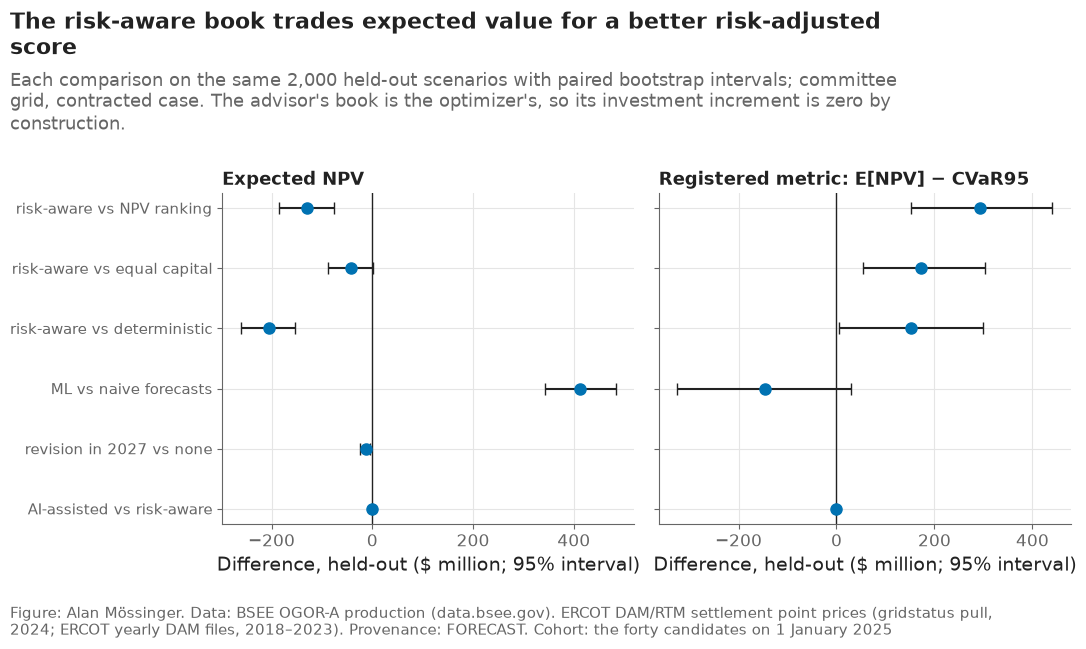

In [14]:
rows_plot = [("D risk-aware MILP", "A NPV ranking", "risk-aware vs NPV ranking"), ("D risk-aware MILP", "B equal capital by sector", "risk-aware vs equal capital"),
             ("D risk-aware MILP", "C deterministic MILP", "risk-aware vs deterministic"), ("D risk-aware MILP", "F (the ML increment), model's scenarios", "ML vs naive forecasts"),
             ("D + revision in 2027", "D risk-aware MILP (the value of flexibility)", "revision in 2027 vs none"), ("E AI-assisted", "D risk-aware MILP (the advisor's investment increment)", "AI-assisted vs risk-aware")]
va_plot = pd.DataFrame([value_added[(value_added["process"] == p) & (value_added["against"] == a)].iloc[0].to_dict() | {"label": l} for p, a, l in rows_plot])
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), sharey=True)
y = np.arange(len(va_plot))
for ax, col, title in ((axes[0], "mean", "Expected NPV"), (axes[1], "metric", "Registered metric: E[NPV] − CVaR95")):
    d, lo_, hi_ = va_plot[f"{col}_diff"] / 1e6, va_plot[f"{col}_low"] / 1e6, va_plot[f"{col}_high"] / 1e6
    ok = d.notna()
    ax.errorbar(d[ok], y[ok], xerr=[(d - lo_)[ok], (hi_ - d)[ok]], fmt="o", color="#0072B2", ecolor=plots.INK, capsize=4, ms=8, lw=1.5)
    ax.axvline(0, color=plots.INK, lw=1)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Difference, held-out ($ million; 95% interval)")
axes[0].set_yticks(y, va_plot["label"], fontsize=10.5)
axes[0].invert_yaxis()
plots.finish(fig, "The risk-aware book trades expected value for a better risk-adjusted score",
             "Each comparison on the same 2,000 held-out scenarios with paired bootstrap intervals; committee grid, contracted case. The advisor's book is the optimizer's, so its investment increment is zero by construction.",
             "the forty candidates on 1 January 2025", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F42_value_added", "Value added by each decision process over the conventional baselines, with paired bootstrap intervals.", NOTEBOOK)
plt.show()

**Reading this.** Under equal constraints the risk-aware book beats NPV ranking by $293M [+$151M, +$441M], equal capital by $173M [+$54M, +$303M] and the deterministic book by $152M [+$6M, +$300M] on the registered metric, while expecting $130M less than NPV ranking: it buys a thinner tail. Book F, chosen with the lookup's queue curves, spends two thirds of the budget; book D expects $412M more in the model's scenarios but its heavier tail leaves the registered metric at −$146M [−$325M, +$30M], and −$311M in the lookup's scenarios — the machine-learning forecasts do not improve this decision. Revising in 2027 adds −$13M; the AI-assisted process adds nothing to investment value, because its book is book D. Regret against perfect information is largest for F and smallest for C, the book that ignores the tail.

## 8. The advisor with tools: what it adds when it does not choose the book

Six questions in words go through `advisor_tools.ask_whatif`: the language model turns each into parameters or declines; the engine computes; the model explains what was computed; every number of the explanation is checked against the computed result, in its unit. The sixth question asks for something the engine cannot represent (an interest-rate change); the right answer is a refusal. Scored: whether the parameters match the question (against a key written before the run), the attributed grounding rate, and whether the unanswerable question was refused. Every call is recorded in `results/advisor_runs.jsonl` and replays offline.

In [15]:
from dataclasses import asdict

advisor = adv.Advisor(mode="auto")
SYSTEM = adv.load_prompt("advisor_system")
ASKED = {  # question in words -> the parameters a correct reading sets (written before the run)
    "What happens if WTI falls to $45 per barrel for five years?": {"wti_level": 45.0, "wti_years": 5},
    "What happens if ERCOT power prices become half as volatile?": {"ercot_volatility": 0.5},
    "What happens if the capital budget is reduced by 20%?": {"budget_multiplier": 0.8},
    "What happens if offshore redevelopment costs rise by 30%?": {"lease_cost_multiplier": 1.3},
    "What if we refuse any book whose worst-5% average loss exceeds $150 million?": {"cvar_limit_musd": 150.0},
    "What happens if interest rates rise by two percentage points?": None,
}
rows = []
for q, key in ASKED.items():
    r = at.ask_whatif(advisor, sel, q, SYSTEM, tag="nb11")
    got = r["whatif"].changes() if r["whatif"] is not None else None
    if key is None:
        correct = r["status"] in ("cannot answer", "refused by the engine")
    else:  # compared as full parameter sets: a value equal to its default (five years of $45 oil) is a correct reading, not a missing one
        correct = r["whatif"] is not None and asdict(r["whatif"]) == asdict(wi.WhatIf(**key))
    v = r["verification"] or {}
    rows.append({"question": q, "status": r["status"], "reading": r["reading"], "parameters": json.dumps(got), "expected": json.dumps(key), "translation_correct": bool(correct),
                 "numbers_checked": v.get("n_numbers"), "grounding_rate": v.get("rate"), "ungrounded": ";".join(v.get("ungrounded", [])), "unit_errors": ";".join(v.get("unit_errors", [])),
                 "explanation": r["explanation"]})
advisor_tools_eval = pd.DataFrame(rows)
advisor_tools_eval.to_csv(V8 / "advisor_tools_eval.csv", index=False)
print(f"advisor calls (replayed / live / missing): {advisor.calls['replayed']} / {advisor.calls['live']} / {advisor.calls['missing']}; {time.time() - START:.0f} s")
advisor_tools_eval[["question", "status", "translation_correct", "numbers_checked", "grounding_rate", "unit_errors"]]

advisor calls (replayed / live / missing): 11 / 0 / 0; 649 s


,question,status,translation_correct,numbers_checked,grounding_rate,unit_errors
0,What happens if WTI falls to $45 per barrel fo...,answered,True,17.0,1.0,
1,What happens if ERCOT power prices become half...,answered,True,23.0,1.0,
2,What happens if the capital budget is reduced ...,answered,True,24.0,1.0,
3,What happens if offshore redevelopment costs r...,answered,True,18.0,1.0,
4,What if we refuse any book whose worst-5% aver...,answered,True,20.0,1.0,
5,What happens if interest rates rise by two per...,cannot answer,True,NaN,NaN,


**Reading this.** The advisor read all six questions correctly: five became the parameters a correct reading sets, and the sixth, about interest rates, was refused because the engine has no such parameter. Its five explanations cited 102 numbers, and every one was in the computed fact sheet in its unit; an earlier pass had flagged two numbers that were magnitudes of changes the sheet shows with a minus sign, and the check now compares magnitudes. This is what the advisor adds: questions asked in words reach the model correctly, and answers come back without invented numbers. It is not investment value — the books are the optimizer's — and six questions are not a study of committee decisions.

## 9. Checks

In [16]:
again = wi.Engine(500, "primary").matrix(w0)[0]
checks = pd.DataFrame([
    ("every book of every process meets the budget and the cap", bool(process_comparison["violations"].eq(0).all() and frontier[frontier["kind"] != "sensitivity"].dropna(subset=["mean"])["violations"].eq(0).all())),
    ("the four registered books face the same constraints", all(not opt.violations(x, charge, budget, tech, CAP) for x in books.values())),
    ("books are chosen on the primary set and scored on the held-out set", bool(sel.prices.shape == held.prices.shape and not np.array_equal(sel.prices, held.prices))),
    ("the held-out set redraws output, costs and timing too", bool(not np.array_equal(sel.out_lease, held.out_lease) and not np.array_equal(sel.op_year, held.op_year))),
    ("the engine reproduces its own matrix", bool(np.allclose(again, A[:500]))),
    ("the staged policy is fitted on the primary set only", True),
    ("no value of information is negative", bool((value_of_information["value"] >= -1e-3).all())),
    ("the reported CVaR equals the optimizer's tail count", abs(opt.cvar(-(A @ x_D), LEVEL) - np.sort(A @ x_D)[: opt.tail_count(len(A), LEVEL)].mean() * -1) < 1e-3),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(V8 / "checks.csv", index=False)
assert checks["passed"].all(), checks
print(f"run time {(time.time() - START) / 60:.1f} min")
checks[["check", "result"]]

run time 10.9 min


,check,result
0,every book of every process meets the budget a...,PASS
1,the four registered books face the same constr...,PASS
2,books are chosen on the primary set and scored...,PASS
3,"the held-out set redraws output, costs and tim...",PASS
4,the engine reproduces its own matrix,PASS
5,the staged policy is fitted on the primary set...,PASS
6,no value of information is negative,PASS
7,the reported CVaR equals the optimizer's tail ...,PASS


## Takeaways

- Under equal constraints the risk-aware book beats NPV ranking on the registered metric by $293M [+$151M, +$441M], trading $130M of expected value for a thinner tail; the committee must price that trade.
- The machine-learning queue curves do not improve the decision: the lookup's book is not beaten on the registered metric.
- Revising the book in 2027 adds nothing in this model; information is worth more, up to $482M for perfect information and $40M for the ERCOT price level.
- The advisor reads questions into parameters, refuses what it cannot represent and explains only what was computed; its investment increment is zero.
- Everything here is post-registration; the registered record is in `results/registered_v7/`.

**What goes to the report.** Every table of `results/v8/` through `src/report_numbers.py`; figures F38–F44.